# 01 - Exploratory Data Analysis (EDA)

## Contexte

Ce notebook réalise l'analyse exploratoire du dataset AgriLens après la phase d'audit qualité et de correction du data leakage.

L'analyse s'appuie sur l'inventaire final `inventory_v3.csv`, issu du Data Quality Report.

## Objectifs

- analyser la distribution des 17 classes ;
- analyser la répartition des cultures ;
- comparer les sources de données ;
- étudier les caractéristiques géométriques des images ;
- identifier les déséquilibres du dataset ;
- détecter d'éventuels biais visuels ;
- préparer les décisions de modélisation.

## Dataset analysé

- Nombre d'images : 26 397
- Nombre de cultures : 3
- Nombre de classes : 17

## Livrables attendus

- Class Mapping
- Audit des volumes et du déséquilibre des classes
- Audit de l'hétérogénéité des sources
- Audit spatial et géométrique
- Audit des surfaces par culture
- Inspection visuelle d'échantillons
- EDA Report

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("EDA Ready")

EDA Ready


In [3]:
df = pd.read_csv("../01_data/metadata/inventory_v3.csv")
df.shape

(26397, 20)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26397 entries, 0 to 26396
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   source           26397 non-null  str    
 1   culture          26397 non-null  str    
 2   split            26397 non-null  str    
 3   classe           26397 non-null  str    
 4   filename         26397 non-null  str    
 5   filepath         26397 non-null  str    
 6   extension        26397 non-null  str    
 7   format           26397 non-null  str    
 8   width            26397 non-null  int64  
 9   height           26397 non-null  int64  
 10  mode             26397 non-null  str    
 11  channels         26397 non-null  int64  
 12  problem          26397 non-null  str    
 13  ratio            26397 non-null  float64
 14  brightness_mean  26397 non-null  float64
 15  exposure_status  26397 non-null  str    
 16  md5_hash         26397 non-null  str    
 17  duplicate_exact  26397 

In [5]:
df["classe"].unique()

<StringArray>
[                                     'black_pod_rot',
                                            'healthy',
                                          'pod_borer',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
                        'Corn_(maize)___Common_rust_',
                             'Corn_(maize)___healthy',
                'Corn_(maize)___Northern_Leaf_Blight',
                            'Tomato___Bacterial_spot',
                              'Tomato___Early_blight',
                                   'Tomato___healthy',
                               'Tomato___Late_blight',
                                 'Tomato___Leaf_Mold',
                        'Tomato___Septoria_leaf_spot',
      'Tomato___Spider_mites Two-spotted_spider_mite',
                               'Tomato___Target_Spot',
                       'Tomato___Tomato_mosaic_virus',
             'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Length: 17, dtype: str

In [6]:
df["classe"].nunique()

17

In [7]:
#L'Audit des Volumes et du Déséquilibre de Classes

In [8]:
df["classe"].value_counts().sort_values(ascending=False)

classe
Tomato___Tomato_Yellow_Leaf_Curl_Virus                5357
healthy                                               3344
Tomato___Bacterial_spot                               2127
Tomato___Late_blight                                  1906
Tomato___Septoria_leaf_spot                           1771
Tomato___Spider_mites Two-spotted_spider_mite         1676
Tomato___healthy                                      1589
Tomato___Target_Spot                                  1404
Corn_(maize)___Common_rust_                           1192
Corn_(maize)___healthy                                1162
Tomato___Early_blight                                 1000
Corn_(maize)___Northern_Leaf_Blight                    985
Tomato___Leaf_Mold                                     952
black_pod_rot                                          943
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
Tomato___Tomato_mosaic_virus                           373
pod_borer                                        

In [9]:
class_counts =(
    df["classe"].value_counts().sort_values(ascending=False).reset_index())

In [10]:
class_counts.columns

Index(['classe', 'count'], dtype='str')

C:\Users\HP\AppData\Local\Temp\ipykernel_6556\3294129804.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Text(0, 0.5, 'classe')

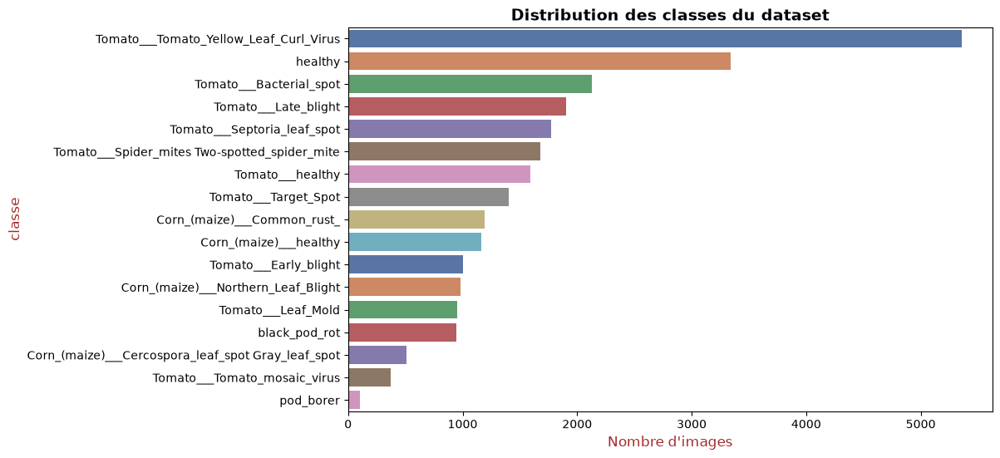

In [11]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=class_counts,
    x="count",
    y="classe",
    palette="deep"
)

plt.title("Distribution des classes du dataset", fontsize=14, fontweight="bold")
plt.xlabel("Nombre d'images",fontsize=12, color="brown")
plt.ylabel("classe",fontsize=12, color="brown")

## Interprétation

Le graphique met en évidence un fort déséquilibre entre les classes.

Certaines classes disposent de plusieurs milliers d'images, comme :

- Tomato___Tomato_Yellow_Leaf_Curl_Virus (5 357 images)

alors que d'autres ne possèdent qu'un nombre limité d'exemples, comme :

- pod_borer (103 images)

Le rapport entre la classe la plus représentée et la moins représentée est supérieur à 50, ce qui confirme un déséquilibre important du dataset.

Les classes issues des jeux de données académiques (Tomate et Maïs) disposent globalement d'un volume beaucoup plus important que les classes du Cacao issues du terrain.

## Décision ML

L'Accuracy globale ne constitue pas une métrique suffisante pour évaluer les performances du futur modèle.

En présence d'un déséquilibre important, un modèle pourrait obtenir une Accuracy élevée en favorisant les classes majoritaires tout en produisant de mauvaises prédictions sur les classes minoritaires.

Les futures expérimentations devront donc être pilotées principalement par :

- F1-Score Macro ;
- Precision Macro ;
- Recall Macro.

Ces métriques accordent le même poids à chacune des 17 classes indépendamment de leur fréquence dans le dataset.

In [12]:
 ## L'Audit de l'Hétérogénéité des Sources

In [13]:
df.groupby("source")["width"].describe()

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
PlantVillage,22007.0,256.00000,0.000000,256.0,256.0,256.0,256.0,256.0
cacao_diseases,4390.0,1298.70615,434.065872,1080.0,1080.0,1080.0,1080.0,2160.0


In [14]:
# PlantVillage est un dataset académique fortement contrôlé et standardisé.

#Toutes les images possèdent une largeur identique de 256 pixels.

#À l'inverse, le dataset cacao_diseases présente plusieurs résolutions et une dispersion beaucoup plus importante, caractéristique de photographies collectées en conditions réelles.

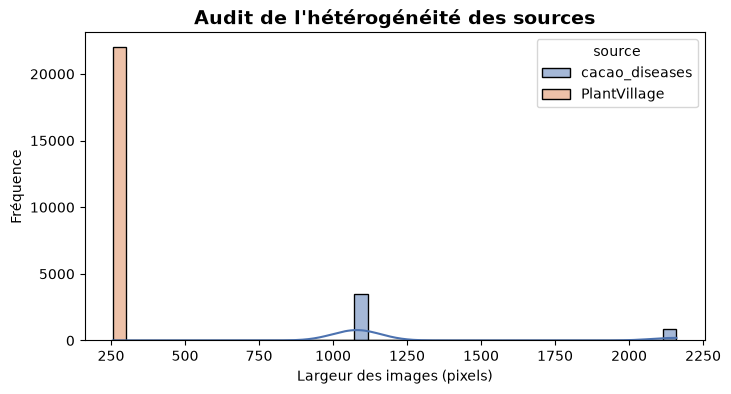

In [15]:
plt.figure(figsize=(8,4))
sns.histplot(
    data=df,
    x="width",
    hue="source",
    binwidth=45,
    multiple="layer",
    kde=True,
    palette="deep",
    alpha=0.5
)
plt.title(
    "Audit de l'hétérogénéité des sources",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Largeur des images (pixels)"
)

plt.ylabel(
    "Fréquence"
)

plt.show()

## Interprétation

Le graphique met en évidence une forte hétérogénéité entre les deux sources de données.

PlantVillage présente une distribution parfaitement standardisée avec une largeur unique de 256 pixels pour l'ensemble des images. Cette homogénéité est caractéristique d'un dataset académique contrôlé.

À l'inverse, la source cacao_diseases présente plusieurs résolutions distinctes, principalement autour de 1080 et 2160 pixels, révélant une plus grande variabilité des conditions d'acquisition.

L'absence de chevauchement entre les distributions montre que les deux sources ont été construites selon des protocoles différents.

Cette différence illustre la transition entre des images produites dans un environnement expérimental contrôlé et des images acquises dans des conditions de terrain réelles.

## Décision ML

Les futures étapes de prétraitement devront appliquer une stratégie de redimensionnement uniforme afin d'obtenir des entrées homogènes pour le modèle.

Les images seront converties vers une résolution unique de 224 × 224 pixels avant l'entraînement de MobileNetV2.

Cette standardisation permettra au réseau de neurones de recevoir des tenseurs de dimensions identiques tout en réduisant l'impact des différences de résolution entre les sources.

In [16]:
#L'Audit Spatial et Géométrique Composite 

In [65]:
df.groupby(["width" ,"height"]).size().sort_values(ascending=False)

width  height
256    256       22007
1080   1080       3501
2160   2160        889
dtype: int64

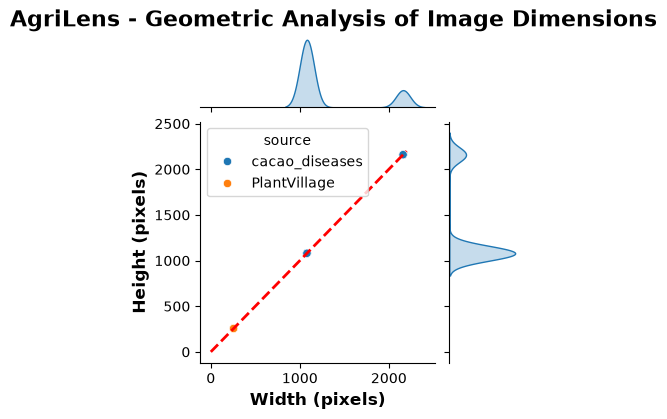

In [69]:
g = sns.jointplot(
    data=df,
    x="width",
    y="height",
    kind="scatter",
    hue="source",
    ratio=3,
    height=4,
    marginal_kws=dict(fill=True)
)

# Diagonale théorique
g.ax_joint.plot(
    [0, 2200],
    [0, 2200],
    color="red",
    linestyle="--",
    linewidth=2
)

# Labels
g.ax_joint.set_xlabel(
    "Width (pixels)",
    fontsize=12,
    fontweight="bold"
)

g.ax_joint.set_ylabel(
    "Height (pixels)",
    fontsize=12,
    fontweight="bold"
)

# Titre
g.figure.suptitle(
    "AgriLens - Geometric Analysis of Image Dimensions",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.show()

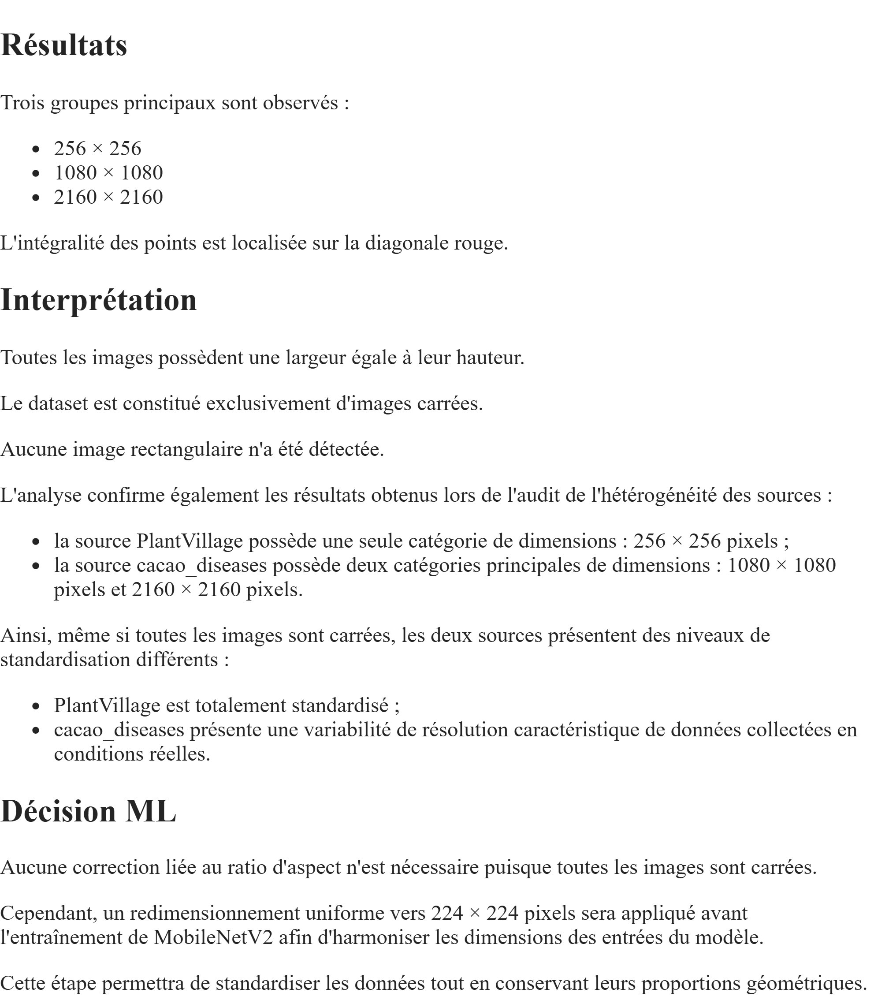

In [19]:
# L'Audit de Dispersion des Surfaces par Culture

In [20]:
df["surface"] = (
    df["width"]
    * df["height"]
)

In [21]:
df["surface"].describe()


count    2.639700e+04
mean     3.664634e+05
std      8.847898e+05
min      6.553600e+04
25%      6.553600e+04
50%      6.553600e+04
75%      6.553600e+04
max      4.665600e+06
Name: surface, dtype: float64

In [22]:
df["surface"].head()

0    1166400
1    1166400
2    1166400
3    1166400
4    1166400
Name: surface, dtype: int64

In [23]:
df.groupby("culture")["surface"].describe()

,count,mean,std,min,25%,50%,75%,max
culture,,,,,,,,
Cacao,4390.0,1.875008e+06,1.406373e+06,1166400.0,1166400.0,1166400.0,1166400.0,4665600.0
Corn_(maize),3852.0,6.553600e+04,0.000000e+00,65536.0,65536.0,65536.0,65536.0,65536.0
Tomato,18155.0,6.553600e+04,0.000000e+00,65536.0,65536.0,65536.0,65536.0,65536.0


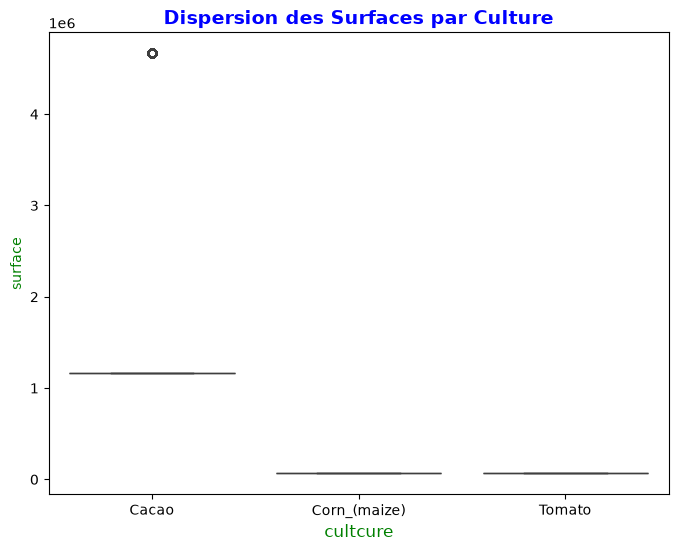

In [24]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df,
    x="culture",
    y="surface",
    
)

plt.title("Dispersion des Surfaces par Culture", fontsize=14, fontweight="bold", color="blue" )
plt.xlabel("cultcure",fontsize=12,color="green")
plt.ylabel("surface", color="green")
plt.show()

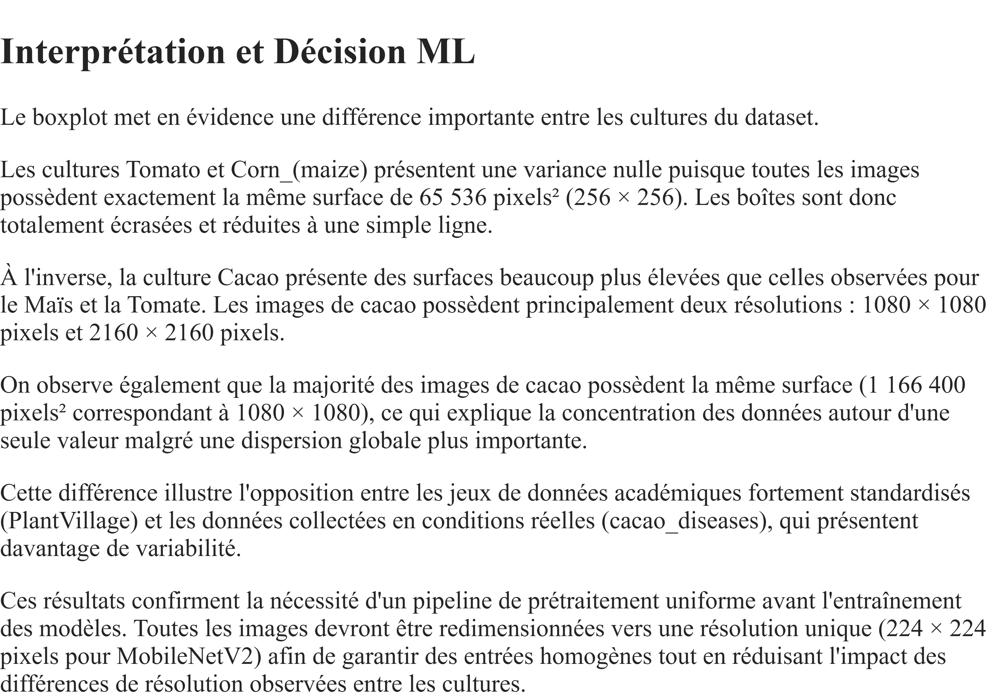

In [25]:
#L'Inspection Visuelle d'Échantillons (Le "Sanity Inspection")
#afficher 5 plante  par classe de facon aleatoire pour analyse le contexte dans lequel chaque image pourait etres prise par classe

In [26]:
sample_images=df[
    df["classe"] == "Tomato___healthy"
].sample(
    n=5,
    random_state=42
)

In [27]:
sample_images["filepath"].head()

11051    ..\..\01_data\raw\PlantVillage\train\Tomato___...
10377    ..\..\01_data\raw\PlantVillage\train\Tomato___...
23615    ..\..\01_data\raw\PlantVillage\val\Tomato___he...
10211    ..\..\01_data\raw\PlantVillage\train\Tomato___...
10582    ..\..\01_data\raw\PlantVillage\train\Tomato___...
Name: filepath, dtype: str

In [28]:
from pathlib import Path

Path.cwd()

WindowsPath('C:/Users/HP/Desktop/mon_projet_personnel/AgrisLens/02_eda')

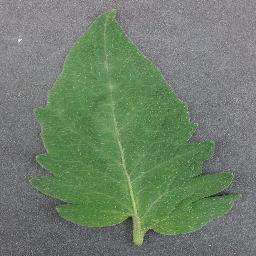

In [29]:
from PIL import Image
test_path = sample_images["filepath"].iloc[0]

test_path = test_path.replace(
    r"..\..\01_data",
    r"../01_data"
)

Image.open(test_path)

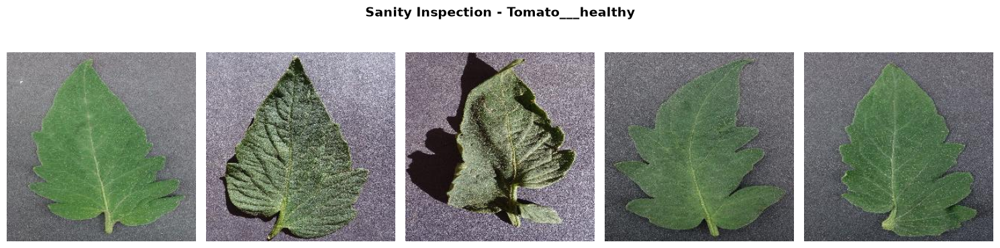

In [30]:
from PIL import Image
import matplotlib.pyplot as plt

# 5 images aléatoires reproductibles

sample_images = df[
    df["classe"] == "Tomato___healthy"
].sample(
    n=5,
    random_state=42
)

# Création de la figure

fig, axes = plt.subplots(
    1,
    5,
    figsize=(15, 4)
)
    
# Affichage des images

for ax, path in zip(
    axes,
    sample_images["filepath"]
):

    path = path.replace(
        r"..\..\01_data",
        r"../01_data"
    )

    img = Image.open(path)

    ax.imshow(img)

    ax.axis("off")

plt.suptitle(
    "Sanity Inspection - Tomato___healthy",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

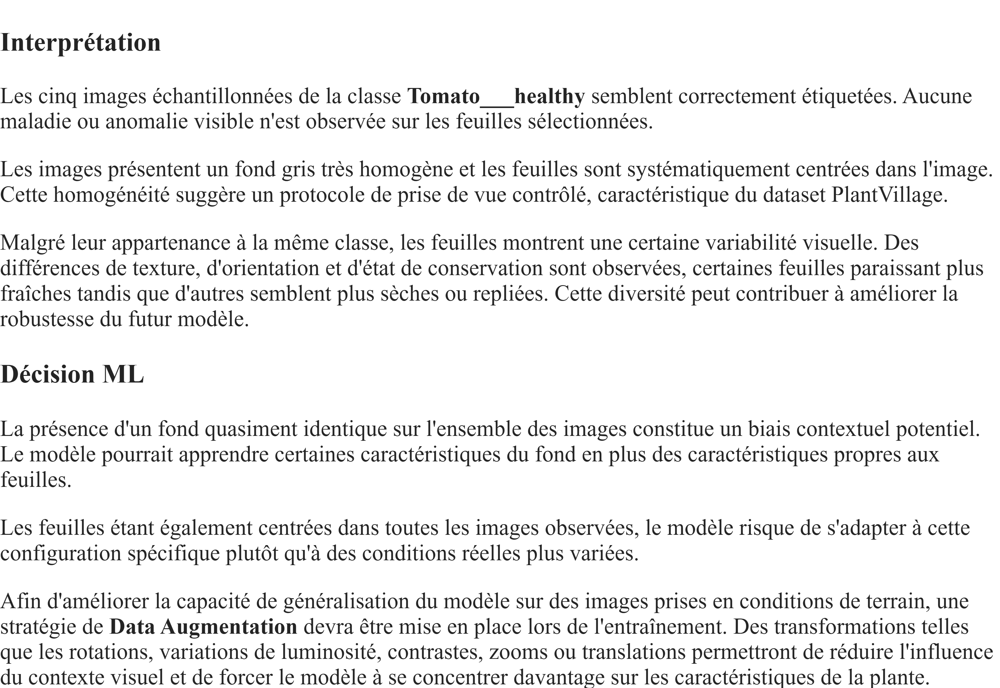

In [31]:
df["classe"].unique()

<StringArray>
[                                     'black_pod_rot',
                                            'healthy',
                                          'pod_borer',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
                        'Corn_(maize)___Common_rust_',
                             'Corn_(maize)___healthy',
                'Corn_(maize)___Northern_Leaf_Blight',
                            'Tomato___Bacterial_spot',
                              'Tomato___Early_blight',
                                   'Tomato___healthy',
                               'Tomato___Late_blight',
                                 'Tomato___Leaf_Mold',
                        'Tomato___Septoria_leaf_spot',
      'Tomato___Spider_mites Two-spotted_spider_mite',
                               'Tomato___Target_Spot',
                       'Tomato___Tomato_mosaic_virus',
             'Tomato___Tomato_Yellow_Leaf_Curl_Virus']
Length: 17, dtype: str

In [32]:
# pour tomato_late_blight

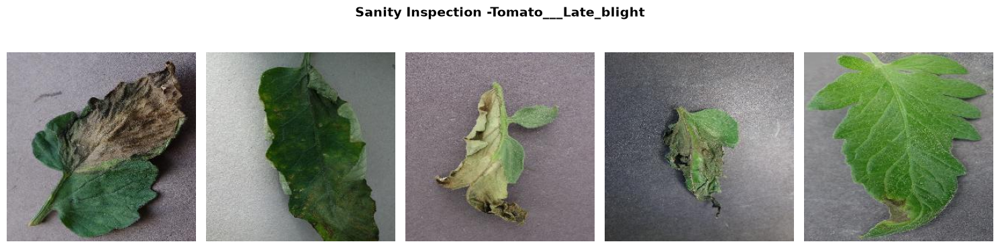

In [33]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Late_blight"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Late_blight",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Late_blight présentent des symptômes caractéristiques de la maladie, notamment des zones brunies, noircies et desséchées sur les feuilles.

Une importante variabilité intra-classe est observée. Certaines feuilles présentent des lésions limitées tandis que d'autres sont fortement dégradées. Cette diversité reflète probablement différents stades d'évolution de la maladie au sein du dataset.

Comme pour la classe Tomato___healthy, les feuilles sont généralement centrées et photographiées sur un fond gris homogène. Aucun artefact particulier (main, outil, texte ou élément extérieur) n'est visible dans les images observées.

## Décision ML
La diversité des symptômes observés au sein d'une même classe est un élément favorable pour l'apprentissage du modèle, car elle lui permet de reconnaître la maladie dans différents états de développement.

Cependant, la forte homogénéité du fond et du cadrage constitue toujours un biais contextuel potentiel. Le modèle pourrait apprendre partiellement les conditions de prise de vue au lieu de se concentrer exclusivement sur les caractéristiques pathologiques des feuilles.

La future stratégie de Data Augmentation devra donc introduire davantage de variabilité géométrique et visuelle afin d'améliorer la capacité de généralisation du modèle sur des images réelles prises en conditions de terrain.

In [ ]:
# pour Tomato___Leaf_Mold

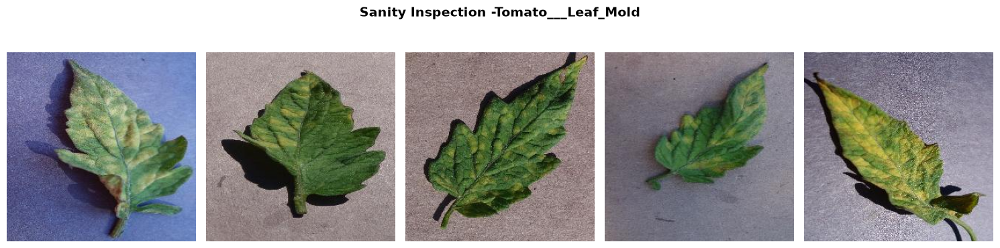

In [34]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Leaf_Mold"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Leaf_Mold",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation

Les cinq images échantillonnées de la classe Tomato___Leaf_Mold présentent des symptômes visuellement cohérents avec cette maladie. Les feuilles restent majoritairement vertes mais présentent des zones jaunâtres et décolorées réparties sur différentes parties du limbe.

Une importante hétérogénéité intra-classe est observée. Certaines feuilles sont légèrement atteintes tandis que d'autres présentent une décoloration beaucoup plus prononcée. Cette variabilité suggère la présence de différents stades d'évolution de la maladie au sein du dataset.

Contrairement à la classe Tomato___Late_blight, les symptômes observés semblent plus diffus et répartis sur l'ensemble de la feuille plutôt que concentrés sous forme de lésions fortement nécrosées. Cette différence visuelle pourrait faciliter la séparation des classes par le futur modèle de classification.

Comme pour les précédentes classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent généralement centrées dans l'image. Aucun artefact particulier n'a été observé.

## Décision ML
La diversité des niveaux d'infestation observés constitue un avantage pour l'apprentissage du modèle, car celui-ci sera exposé à plusieurs manifestations de la maladie.

Cependant, l'homogénéité du fond et du cadrage reste présente et constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra être utilisée afin de réduire la dépendance du modèle aux conditions de prise de vue et de favoriser l'apprentissage des symptômes réellement associés à la maladie.

In [35]:
# pour  Tomato___Septoria_leaf_spot

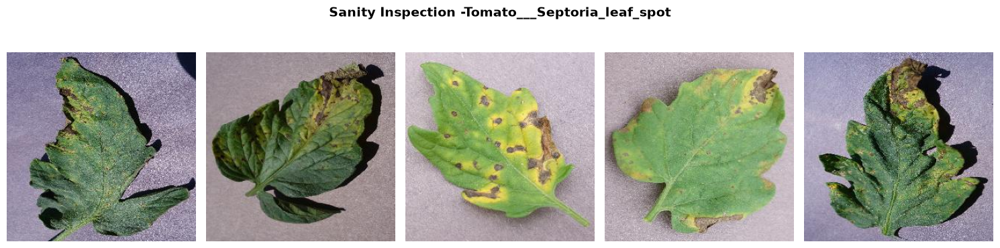

In [36]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Septoria_leaf_spot"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Septoria_leaf_spot",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Septoria_leaf_spot présentent des symptômes cohérents avec cette maladie. Les feuilles montrent de nombreuses petites taches brunâtres réparties sur différentes zones du limbe. Plusieurs lésions sont entourées de zones jaunâtres, indiquant une dégradation localisée des tissus.

Une importante hétérogénéité intra-classe est observée. Le nombre, la taille et la répartition des taches varient d'une feuille à l'autre. Certaines feuilles sont légèrement atteintes tandis que d'autres présentent une concentration beaucoup plus importante de lésions.

Contrairement aux classes Tomato___Late_blight et Tomato___Leaf_Mold, les symptômes sont principalement caractérisés par de multiples taches distinctes dispersées sur la feuille plutôt que par de larges zones nécrosées ou un jaunissement diffus. Cette différence visuelle renforce la séparabilité entre les classes.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent généralement centrées dans l'image. Aucun artefact particulier n'a été observé.

## Décision ML
La diversité des symptômes observés permet au futur modèle d'être exposé à plusieurs niveaux de sévérité de la maladie, ce qui peut améliorer sa capacité de généralisation.

Les symptômes observés semblent visuellement distincts de ceux des autres maladies déjà analysées, ce qui constitue un signal favorable pour la classification automatique.

Cependant, l'homogénéité du fond et du cadrage reste présente et représente un biais contextuel potentiel. Une stratégie de Data Augmentation devra être appliquée afin de réduire l'influence du contexte de prise de vue et de favoriser l'apprentissage des caractéristiques pathologiques des feuilles.

In [37]:
# pour 

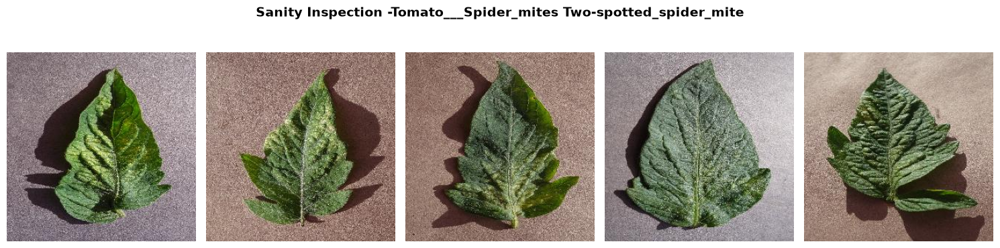

In [38]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Spider_mites Two-spotted_spider_mite"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Spider_mites Two-spotted_spider_mite",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Spider_mites Two-spotted_spider_mite présentent des symptômes cohérents entre elles. Les feuilles restent majoritairement vertes mais présentent de nombreuses zones décolorées et mouchetées réparties sur l'ensemble du limbe.

Une hétérogénéité intra-classe est observée. L'intensité des symptômes varie selon les feuilles, certaines présentant des décolorations plus marquées que d'autres. Malgré cette variabilité, les motifs observés restent globalement similaires au sein de la classe.

Contrairement à Tomato___Late_blight, les tissus ne semblent pas fortement nécrosés. Contrairement à Tomato___Septoria_leaf_spot, les symptômes ne prennent pas principalement la forme de taches brunes distinctes. Les altérations apparaissent davantage sous forme de décolorations diffuses réparties sur la surface de la feuille.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent centrées dans l'image. Aucun artefact particulier n'a été observé.

## Décision ML
Les symptômes observés semblent suffisamment distincts de ceux des autres maladies déjà analysées pour constituer des caractéristiques discriminantes exploitables par le futur modèle.

La variabilité du niveau d'infestation observée au sein de la classe permettra également au modèle d'apprendre plusieurs manifestations de la maladie.

Cependant, l'homogénéité du fond et des conditions de prise de vue reste présente et constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra être utilisée pour réduire la dépendance du modèle à ces éléments et favoriser l'apprentissage des caractéristiques visuelles propres aux symptômes.

In [39]:
# pour Tomato___Target_Spot

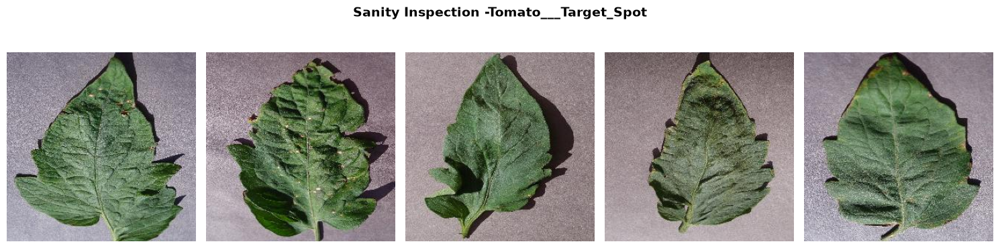

In [40]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Target_Spot"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Target_Spot",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Target_Spot présentent des symptômes visuellement plus discrets que ceux observés dans plusieurs autres maladies précédemment analysées. Les feuilles restent majoritairement vertes et ne présentent pas de larges zones de nécrose ou de dégradation sévère.

Les symptômes observés prennent principalement la forme de petites lésions localisées, de légères décolorations et d'altérations réparties sur différentes zones du limbe. Dans certains cas, les atteintes semblent concentrées sur les bords de la feuille.

Une hétérogénéité intra-classe est également visible. Certaines feuilles présentent très peu de symptômes alors que d'autres montrent davantage de lésions et de décolorations. Cette variabilité reflète probablement différents niveaux d'évolution de la maladie.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent généralement centrées dans l'image. Aucun artefact particulier n'a été observé.

## Décision ML
Les symptômes de la classe Tomato___Target_Spot semblent plus subtils et potentiellement plus difficiles à distinguer que ceux observés dans certaines autres maladies fortement marquées visuellement. Cette classe pourrait donc représenter un défi plus important pour le futur modèle de classification.

La variabilité des symptômes observés constitue néanmoins un atout pour l'entraînement, car elle expose le modèle à plusieurs niveaux de sévérité de la maladie.

L'homogénéité du fond et des conditions de prise de vue reste présente et représente un biais contextuel potentiel. Une stratégie de Data Augmentation devra être appliquée afin de favoriser l'apprentissage des caractéristiques pathologiques de la feuille plutôt que du contexte visuel.

In [ ]:
# pour Tomato___Tomato_mosaic_virus

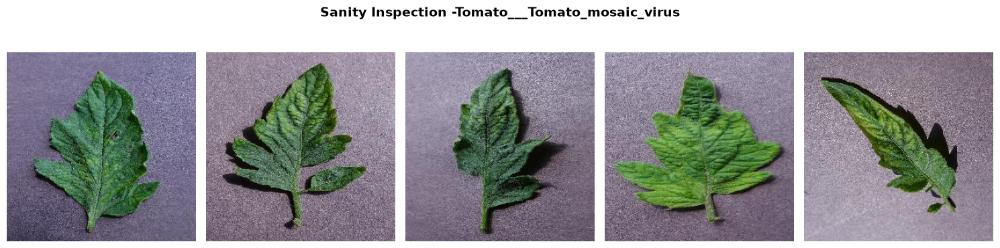

In [41]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Tomato_mosaic_virus"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Tomato_mosaic_virus",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Tomato_mosaic_virus présentent des symptômes cohérents avec cette maladie. Les feuilles restent globalement vertes mais montrent des variations irrégulières de coloration, avec l'alternance de zones vert foncé, vert clair et parfois légèrement jaunâtres.

Une hétérogénéité intra-classe est observée. Certaines feuilles présentent un motif de mosaïque très marqué tandis que d'autres montrent des symptômes plus discrets. Quelques déformations légères de la forme des feuilles sont également visibles.

Contrairement aux classes précédemment analysées, les symptômes ne se manifestent pas principalement par des taches nécrotiques ou des lésions importantes. L'altération de la coloration constitue ici le principal indice visuel permettant d'identifier la maladie.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent généralement centrées dans l'image. Aucun artefact particulier n'a été observé.

## 
Décision ML
Les motifs de coloration observés semblent constituer une signature visuelle distinctive de la maladie et pourront être exploités par le futur modèle de classification.

La variabilité de l'intensité des symptômes permettra au modèle d'apprendre plusieurs manifestations du virus et devrait améliorer sa capacité de généralisation.

Cependant, l'homogénéité du fond et des conditions de prise de vue reste présente et constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra être utilisée afin de limiter l'influence du contexte visuel et de favoriser l'apprentissage des caractéristiques propres à la feuille.

In [42]:
# pour Tomato___Tomato_Yellow_Leaf_Curl_Virus

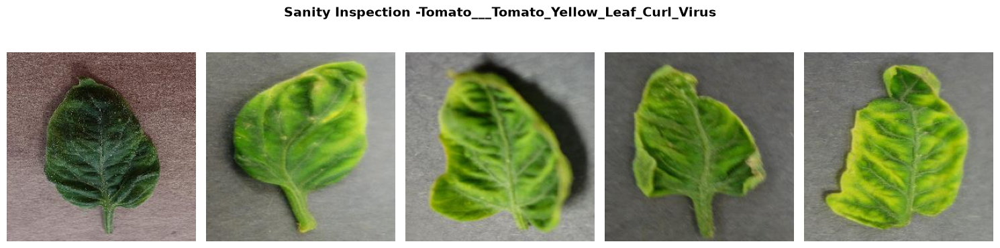

In [43]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Tomato___Tomato_Yellow_Leaf_Curl_Virus"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Tomato___Tomato_Yellow_Leaf_Curl_Virus présentent des symptômes cohérents avec cette maladie. Les feuilles montrent un important jaunissement du limbe tandis que les nervures demeurent visiblement plus vertes, créant un contraste caractéristique.

Une hétérogénéité intra-classe est observée. Certaines feuilles présentent un jaunissement modéré alors que d'autres sont fortement affectées. Plusieurs feuilles semblent également légèrement déformées ou recroquevillées, ce qui constitue un indice supplémentaire associé à la maladie.

Contrairement aux classes présentant des symptômes sous forme de taches ou de lésions nécrotiques, cette maladie se caractérise principalement par une chlorose importante et une modification de la morphologie des feuilles. Ces caractéristiques visuelles semblent relativement distinctes des autres maladies observées jusqu'à présent.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées sur un fond homogène et apparaissent généralement centrées dans l'image. Aucun artefact particulier n'a été observé.

## Décision ML
Le jaunissement marqué des feuilles ainsi que les déformations observées constituent des caractéristiques discriminantes susceptibles d'être exploitées efficacement par le futur modèle de classification.

La présence de différents niveaux d'intensité des symptômes représente un avantage pour l'apprentissage, puisque le modèle sera confronté à plusieurs stades d'évolution de la maladie.

Toutefois, l'homogénéité du fond et des conditions de prise de vue reste présente et constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra être utilisée afin de favoriser l'apprentissage des symptômes réels de la maladie et d'améliorer la capacité de généralisation du modèle.

In [ ]:
# pour Corn_(maize)___healthy

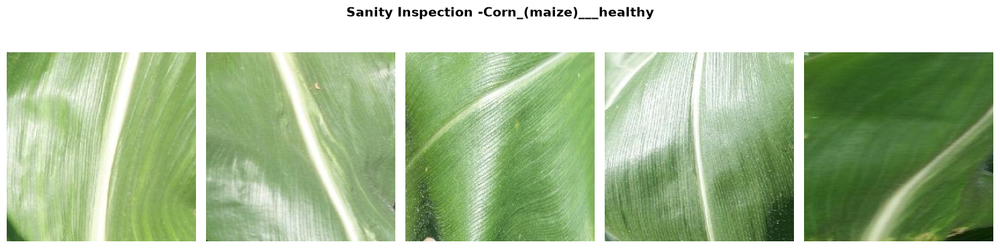

In [47]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Corn_(maize)___healthy"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Corn_(maize)___healthy",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Corn_(maize)___healthy ne présentent aucun symptôme visible de maladie. Les feuilles apparaissent uniformément vertes, avec une texture régulière et des nervures bien définies.

Contrairement aux classes pathologiques analysées précédemment, aucune tache, nécrose, décoloration ou déformation significative n'est observée. Les images semblent correctement étiquetées et cohérentes avec une classe saine.

La variabilité intra-classe est relativement faible. Les différentes images présentent des caractéristiques visuelles très similaires, tant au niveau de la couleur que de la structure des feuilles.

Les images sont réalisées dans un environnement contrôlé avec un fond homogène et sans artefact visible. Le cadrage est fortement centré sur la feuille, ce qui facilite l'observation de ses caractéristiques visuelles.

## Décision ML
Cette classe constitue une référence essentielle pour le futur modèle de classification. Elle permet d'apprendre les caractéristiques normales d'une feuille de maïs en bonne santé et servira de point de comparaison pour distinguer les différentes pathologies.

L'absence de symptômes visibles devrait faciliter la séparation avec certaines maladies fortement marquées. Toutefois, l'homogénéité du fond et des conditions de prise de vue reste présente et constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra donc être mise en place afin d'améliorer la capacité de généralisation du modèle sur des images acquises en conditions réelles. ``

In [45]:
# pour Corn_(maize)___Northern_Leaf_Blight

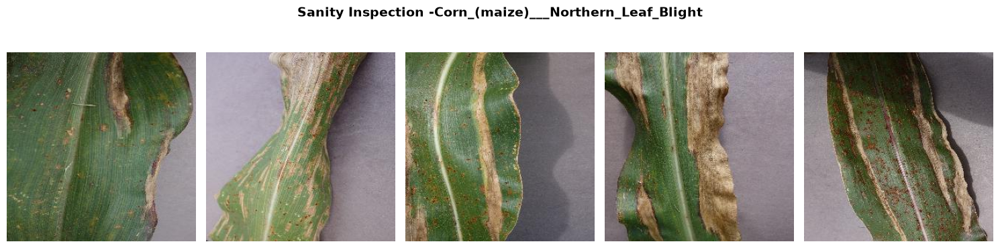

In [50]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Corn_(maize)___Northern_Leaf_Blight"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Corn_(maize)___Northern_Leaf_Blight",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Corn_(maize)___Northern_Leaf_Blight présentent des symptômes cohérents avec cette maladie. Les feuilles montrent de longues lésions brunâtres à beige clair qui s'étendent dans le sens de la longueur de la feuille. Plusieurs zones apparaissent desséchées et nécrosées.

Une hétérogénéité intra-classe est observée. La taille, la forme et l'étendue des lésions varient entre les images. Certaines feuilles présentent des atteintes localisées tandis que d'autres montrent des zones nécrosées plus importantes.

Contrairement aux maladies de la tomate analysées précédemment, les symptômes ne prennent pas principalement la forme de taches circulaires ou de décolorations diffuses. Les lésions apparaissent sous forme de bandes allongées suivant la structure naturelle de la feuille de maïs.

Les images sont prises dans un environnement contrôlé avec un fond homogène et sans artefact visible. Les feuilles sont isolées et clairement mises en évidence, ce qui facilite l'observation des symptômes.

## Décision ML
Les lésions allongées observées constituent une signature visuelle distinctive susceptible d'être exploitée efficacement par le futur modèle de classification.

La variabilité des niveaux d'infestation observés permettra au modèle d'apprendre plusieurs manifestations de la maladie et devrait améliorer sa robustesse.

Cependant, comme pour les autres classes issues de PlantVillage, l'homogénéité du fond et des conditions de prise de vue constitue un biais contextuel potentiel. Une stratégie de Data Augmentation devra être appliquée afin de favoriser l'apprentissage des symptômes réels et d'améliorer la capacité de généralisation du modèle sur des images acquises en conditions réelles. ``

In [ ]:
# pour Corn_(maize)___Common_rust

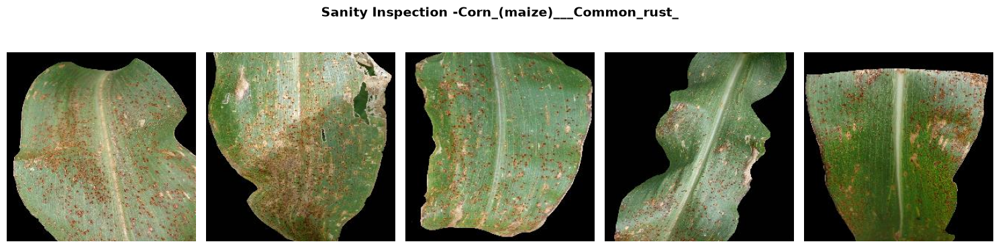

In [52]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Corn_(maize)___Common_rust_"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Corn_(maize)___Common_rust_",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Corn_(maize)__Common_rust présentent des symptômes homogènes et facilement identifiables. Les feuilles montrent un grand nombre de petites lésions brunâtres à orangées réparties sur l'ensemble de leur surface.

Contrairement à Corn_(maize)___Northern_Leaf_Blight, où les symptômes apparaissaient sous forme de longues bandes nécrosées, cette maladie se caractérise par une multitude de petites pustules dispersées. La répartition des lésions est relativement uniforme sur les différentes feuilles observées.

Une hétérogénéité intra-classe est néanmoins présente. Certaines feuilles présentent une densité plus importante de lésions que d'autres, ce qui suggère différents niveaux d'évolution de la maladie. Malgré cette variabilité, les symptômes restent visuellement cohérents au sein de la classe.

Les images sont réalisées dans un environnement contrôlé, avec un fond uniforme et sans artefact visible. Les feuilles sont isolées du reste de la plante, permettant une observation claire des symptômes.

## Décision ML
Les nombreuses lésions brunâtres observées constituent une signature visuelle distinctive qui devrait être facilement exploitable par le futur modèle de classification.

La différence marquée entre les symptômes de Common Rust et ceux de Northern Leaf Blight renforce la séparabilité entre les classes de maladies du maïs. Le modèle pourra ainsi s'appuyer sur des caractéristiques visuelles spécifiques pour différencier ces pathologies.

La variation de densité des lésions observée entre les images permettra également au modèle d'apprendre plusieurs niveaux de sévérité de la maladie, ce qui devrait améliorer sa robustesse.

Cependant, comme pour les autres classes issues de PlantVillage, l'homogénéité du fond et des conditions de prise de vue constitue un biais contextuel potentiel. Une stratégie de Data Augmentation restera nécessaire afin d'améliorer la capacité de généralisation du modèle sur des images acquises en conditions réelles.

In [53]:
# pour Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot

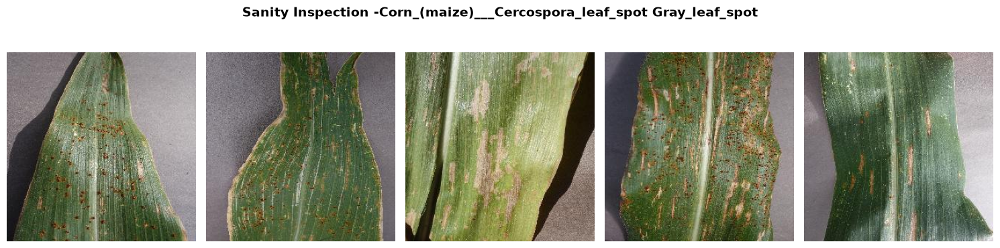

In [54]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection -Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot présentent des symptômes cohérents avec cette maladie. Les feuilles montrent de nombreuses lésions brunâtres à grisâtres réparties sur leur surface. Certaines lésions apparaissent sous forme de plages allongées suivant l'orientation naturelle des nervures de la feuille.

Une hétérogénéité intra-classe est observée. Certaines feuilles présentent principalement de petites lésions dispersées tandis que d'autres montrent des zones décolorées plus étendues. Cette variabilité peut refléter différents stades d'évolution de la maladie.

Les symptômes observés présentent certaines similitudes avec ceux de la classe Corn_(maize)__Common_rust, notamment la présence de nombreuses altérations réparties sur la feuille. Toutefois, les lésions observées ici semblent souvent plus allongées et plus diffuses, avec des zones grisâtres ou beige clair plus développées.

Comme pour les autres classes issues de PlantVillage, les feuilles sont photographiées dans un environnement contrôlé, avec un fond homogène et sans artefact visible. Les feuilles sont clairement isolées du reste de la plante afin de mettre en évidence les symptômes.

## Décision ML
Les similitudes visuelles observées entre Cercospora Leaf Spot (Gray Leaf Spot) et Common Rust suggèrent que leur séparation pourrait être plus complexe que pour certaines autres maladies présentant des symptômes très distinctifs.

Le futur modèle devra apprendre des différences fines portant sur la forme, la taille et la distribution des lésions. L'analyse de ces classes sera particulièrement importante lors de l'étude de la matrice de confusion afin d'identifier d'éventuelles erreurs de classification entre maladies du maïs.

La variabilité observée au sein de la classe constitue un atout pour l'apprentissage. Toutefois, l'homogénéité du fond et des conditions de prise de vue reste un biais contextuel potentiel qui devra être atténué par une stratégie adaptée de Data Augmentation. 

In [ ]:
# pour  healthy

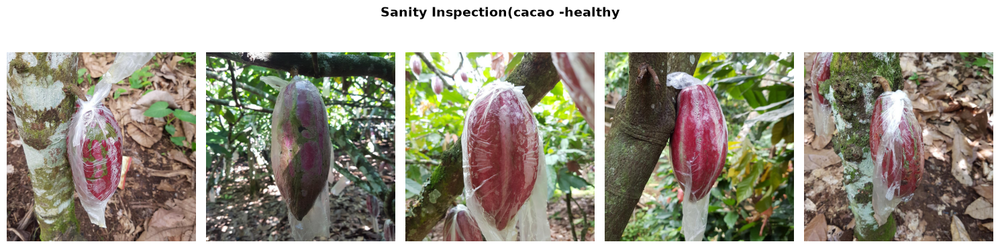

In [57]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="healthy"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection(cacao -healthy",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe cacao_healthy présentent des cabosses visuellement saines, sans symptôme apparent de maladie ou de dégradation. Aucune zone de pourriture, perforation ou nécrose importante n'est observée sur les fruits sélectionnés.

Contrairement aux classes issues de PlantVillage, les images sont prises directement en conditions réelles de culture. Les cabosses sont photographiées sur l'arbre et l'environnement naturel reste visible en arrière-plan. Des feuilles, branches, troncs et éléments du sol apparaissent dans plusieurs images.

Une importante variabilité contextuelle est observée. L'éclairage, l'arrière-plan, l'angle de prise de vue et le cadrage diffèrent d'une image à l'autre. Cette diversité est représentative d'un dataset collecté sur le terrain.

Un élément récurrent attire également l'attention : la présence d'un sachet plastique transparent autour de plusieurs cabosses. Cet élément constitue un artefact contextuel potentiel susceptible d'influencer les prédictions du futur modèle.

## Décision ML
Cette classe confirme que les données cacao ont été acquises dans des conditions réelles beaucoup plus variées que les données PlantVillage. Cette diversité visuelle devrait améliorer la capacité du futur modèle à généraliser sur des images terrain.

Cependant, la présence fréquente de sachets plastiques pourrait introduire un biais si certaines classes de cacao sont plus souvent associées à cet élément que d'autres. Il sera donc nécessaire de vérifier si cet artefact apparaît également dans les autres classes cacao.

Cette observation renforce l'intérêt d'une stratégie de Data Augmentation afin de limiter l'influence de l'arrière-plan et de favoriser l'apprentissage des caractéristiques visuelles réellement associées à l'état sanitaire des cabosses.

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 3)

In [ ]:
# pour 'pod_borer' 

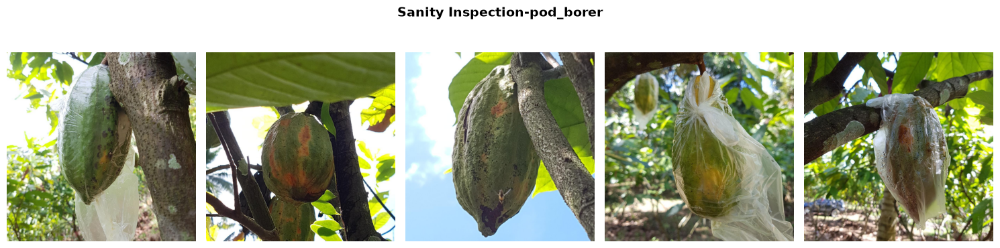

In [59]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="pod_borer"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection-pod_borer",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [ ]:
# pour black_pod_rot

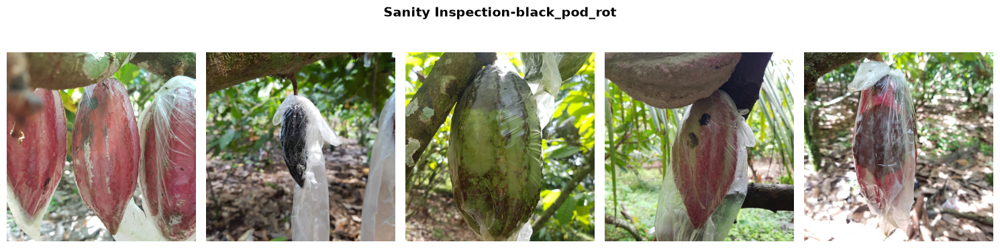

In [60]:
# 5 images aléatoires reproductibles
sample_images=df[
    df["classe"]=="black_pod_rot"
    ].sample(
        n=5,
        random_state=42
    )
# Création de la figure
fig, axes=plt.subplots(
    1,
    5,
    figsize=(15,4)
)
#affichage

for ax, path in zip(
    axes,
    sample_images["filepath"]
):
    path=path.replace(
        r"..\..\01_data",
        r"../01_data"
    )
    img= Image.open(path)
    ax.imshow(img)
    ax.axis("off")
plt.suptitle(
    "Sanity Inspection-black_pod_rot",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

## Interprétation
Les cinq images échantillonnées de la classe black_pod_rot présentent des symptômes clairement visibles sur les cabosses de cacao. Plusieurs fruits montrent d'importantes zones sombres, brunâtres à noirâtres, ainsi que des régions présentant une dégradation avancée des tissus. Certaines cabosses semblent presque entièrement envahies par ces zones nécrosées.

Comme pour les autres classes cacao, les images sont acquises directement sur le terrain. Les cabosses sont photographiées sur l'arbre, avec un arrière-plan naturellement composé de branches, feuilles, troncs et végétation environnante. L'éclairage et les angles de prise de vue varient fortement d'une image à l'autre.

Une hétérogénéité intra-classe est observée. L'étendue des symptômes varie selon les cabosses : certaines présentent uniquement quelques zones atteintes tandis que d'autres montrent une pourriture beaucoup plus développée. Cette diversité suggère la présence de différents stades d'évolution de la maladie.

Comme dans les classes cacao_healthy et pod_borer, la présence fréquente de sachets plastiques transparents est observée autour des cabosses. Cet élément constitue un artefact contextuel récurrent au sein du dataset cacao.

## Décision ML
Les symptômes observés dans la classe black_pod_rot apparaissent particulièrement marqués et visuellement distinctifs. Les importantes zones noirâtres et les signes de pourriture constituent des caractéristiques discriminantes susceptibles d'être facilement exploitées par le futur modèle.

Contrairement à la classe pod_borer, où les altérations semblaient plus diffuses et parfois discrètes, les symptômes de black_pod_rot apparaissent généralement plus étendus et plus sévères. Cette différence pourrait faciliter la séparation entre ces deux maladies lors de la phase de classification.

La forte variabilité des arrière-plans, des conditions d'éclairage et des cadrages reflète des conditions réelles de collecte des données. Cette diversité favorise la généralisation du modèle, mais impose également l'utilisation d'une stratégie de Data Augmentation afin de réduire l'influence du contexte visuel et de renforcer l'apprentissage des caractéristiques propres aux cabosses malades.

## Interprétation
Les cinq images échantillonnées de la classe black_pod_rot présentent des symptômes clairement visibles sur les cabosses de cacao. Plusieurs fruits montrent d'importantes zones sombres, brunâtres à noirâtres, ainsi que des régions présentant une dégradation avancée des tissus. Certaines cabosses semblent presque entièrement envahies par ces zones nécrosées.

Comme pour les autres classes cacao, les images sont acquises directement sur le terrain. Les cabosses sont photographiées sur l'arbre, avec un arrière-plan naturellement composé de branches, feuilles, troncs et végétation environnante. L'éclairage et les angles de prise de vue varient fortement d'une image à l'autre.

Une hétérogénéité intra-classe est observée. L'étendue des symptômes varie selon les cabosses : certaines présentent uniquement quelques zones atteintes tandis que d'autres montrent une pourriture beaucoup plus développée. Cette diversité suggère la présence de différents stades d'évolution de la maladie.

Comme dans les classes cacao_healthy et pod_borer, la présence fréquente de sachets plastiques transparents est observée autour des cabosses. Cet élément constitue un artefact contextuel récurrent au sein du dataset cacao.

## Décision ML
Les symptômes observés dans la classe black_pod_rot apparaissent particulièrement marqués et visuellement distinctifs. Les importantes zones noirâtres et les signes de pourriture constituent des caractéristiques discriminantes susceptibles d'être facilement exploitées par le futur modèle.

Contrairement à la classe pod_borer, où les altérations semblaient plus diffuses et parfois discrètes, les symptômes de black_pod_rot apparaissent généralement plus étendus et plus sévères. Cette différence pourrait faciliter la séparation entre ces deux maladies lors de la phase de classification.

La forte variabilité des arrière-plans, des conditions d'éclairage et des cadrages reflète des conditions réelles de collecte des données. Cette diversité favorise la généralisation du modèle, mais impose également l'utilisation d'une stratégie de Data Augmentation afin de réduire l'influence du contexte visuel et de renforcer l'apprentissage des caractéristiques propres aux cabosses malades.

In [61]:
df["classe"].value_counts().sort_values()

classe
pod_borer                                              103
Tomato___Tomato_mosaic_virus                           373
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
black_pod_rot                                          943
Tomato___Leaf_Mold                                     952
Corn_(maize)___Northern_Leaf_Blight                    985
Tomato___Early_blight                                 1000
Corn_(maize)___healthy                                1162
Corn_(maize)___Common_rust_                           1192
Tomato___Target_Spot                                  1404
Tomato___healthy                                      1589
Tomato___Spider_mites Two-spotted_spider_mite         1676
Tomato___Septoria_leaf_spot                           1771
Tomato___Late_blight                                  1906
Tomato___Bacterial_spot                               2127
healthy                                               3344
Tomato___Tomato_Yellow_Leaf_Curl_Virus           